## Top 20 unpenalized results — logistic auxiliary/segment fits preferred

Completed **unbalanced segmented Gram** study. Restrict to zero explicit L1/L2 penalty; prioritize logistic auxiliary and segment refits, then rank by smallest screening TV distance to the earlier rank-3 curve. There are 216 logistic candidates, so all twenty selected rows use logistic. Finite iteration budgets act as implicit regularization. The solver, budget and intercept choice are matched across the initial auxiliary, segment and posterior regressions. No P(1) cutoff is imposed; probabilities are displayed rather than optimized. Screening uses 512 draws; existing 1024-draw rechecks are overlaid and tabulated where available. Missing rechecks are explicitly marked. This is exploratory shape-based selection, not evidence of statistical calibration.

Logistic auxiliary/segment fits prioritized; within each loss, ascending screening TV. No P(1) threshold.


subset_rank,id,P_1,TV_to_rank3,aux_loss,penalty,strength,method,budget,intercept,Delta,denominator,correlation,peak_age,mass_above55,recheck_count,recheck_P1_min,recheck_P1_max
1,config143_n,1.00000,0.74862,logistic,none,0.00000,fista,30,False,2,n,0.08374,83.00000,1.00000,2,1.00000,1.00000
2,config045_n,1.00000,0.81081,logistic,none,0.00000,gd,100,False,1,n,0.05149,79.00000,1.00000,2,1.00000,1.00000
3,config031_p,1.00000,0.86136,logistic,none,0.00000,fista,30,False,1,p,0.08374,81.00000,1.00000,0,Not rechecked,Not rechecked
4,config045_p,1.00000,0.86136,logistic,none,0.00000,gd,100,False,1,p,0.05149,81.00000,1.00000,0,Not rechecked,Not rechecked
5,config143_p,1.00000,0.86136,logistic,none,0.00000,fista,30,False,2,p,0.08374,81.00000,1.00000,2,1.00000,1.00000
6,config157_p,1.00000,0.86136,logistic,none,0.00000,gd,100,False,2,p,0.05149,81.00000,1.00000,2,1.00000,1.00000
7,config317_p,1.00000,0.86136,logistic,none,0.00000,lbfgs,30,True,5,p,0.07909,81.00000,1.00000,0,Not rechecked,Not rechecked
8,config255_n,1.00000,0.86556,logistic,none,0.00000,fista,30,False,5,n,0.08374,82.00000,1.00000,0,Not rechecked,Not rechecked
9,config031_n,1.00000,0.88226,logistic,none,0.00000,fista,30,False,1,n,0.08374,83.00000,1.00000,0,Not rechecked,Not rechecked
10,config150_n,1.00000,0.88227,logistic,none,0.00000,lbfgs,50,False,2,n,0.13992,83.00000,1.00000,0,Not rechecked,Not rechecked


### Unpenalized #1: config143_n
Screening P(1)=1.0000; TV=0.7486; correlation=0.0837.

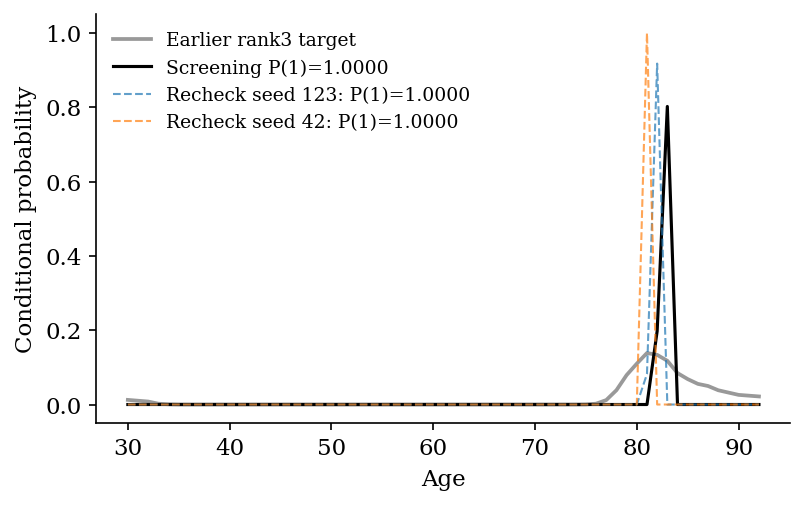

### Unpenalized #2: config045_n
Screening P(1)=1.0000; TV=0.8108; correlation=0.0515.

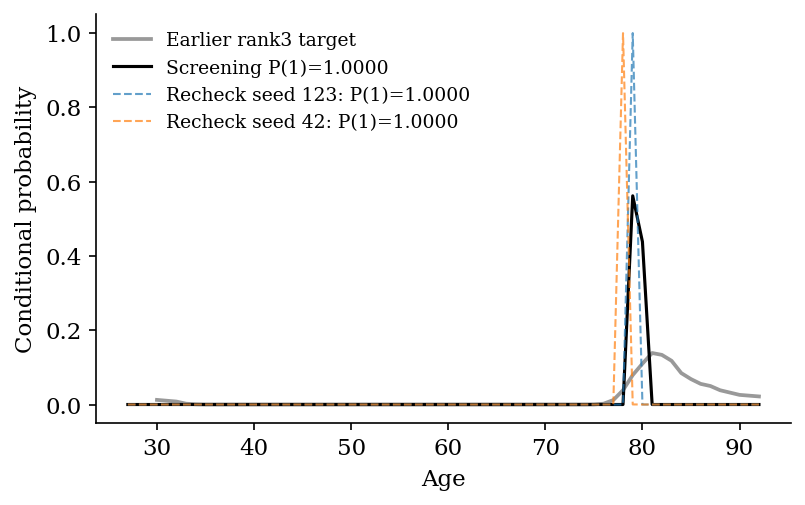

### Unpenalized #3: config031_p
Screening P(1)=1.0000; TV=0.8614; correlation=0.0837.

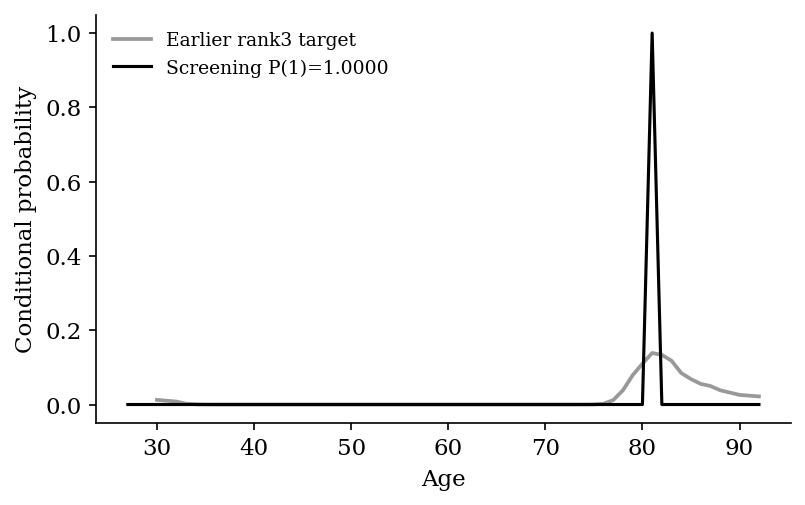

### Unpenalized #4: config045_p
Screening P(1)=1.0000; TV=0.8614; correlation=0.0515.

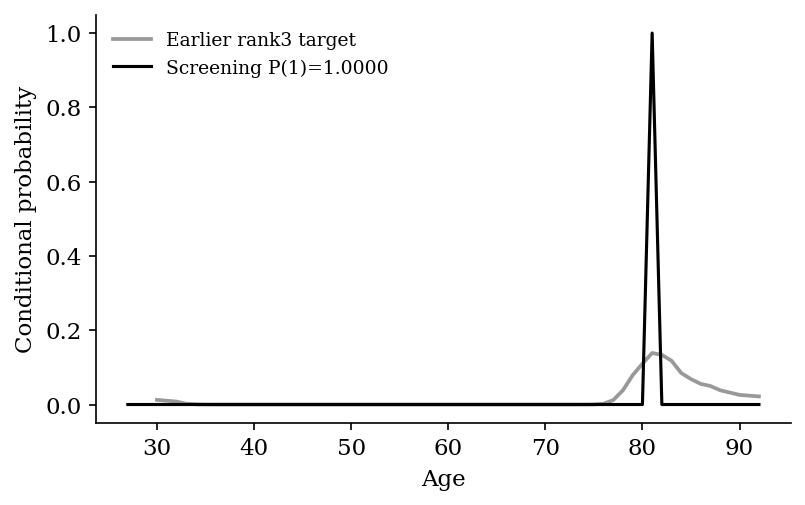

### Unpenalized #5: config143_p
Screening P(1)=1.0000; TV=0.8614; correlation=0.0837.

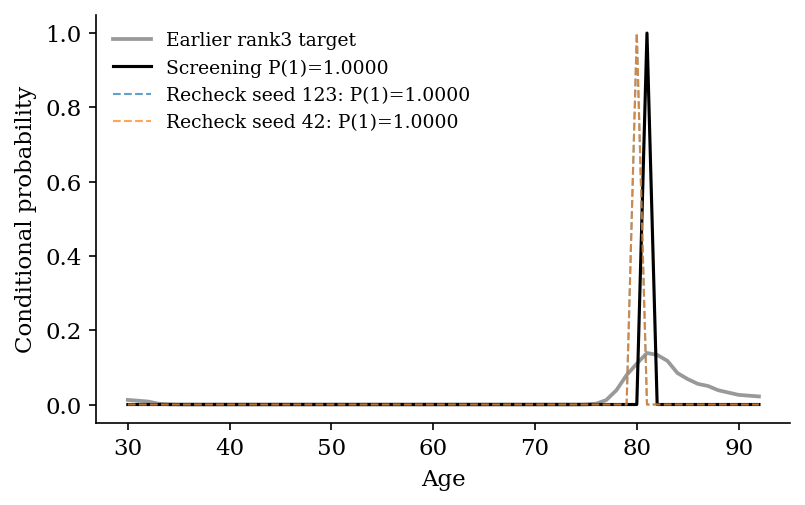

### Unpenalized #6: config157_p
Screening P(1)=1.0000; TV=0.8614; correlation=0.0515.

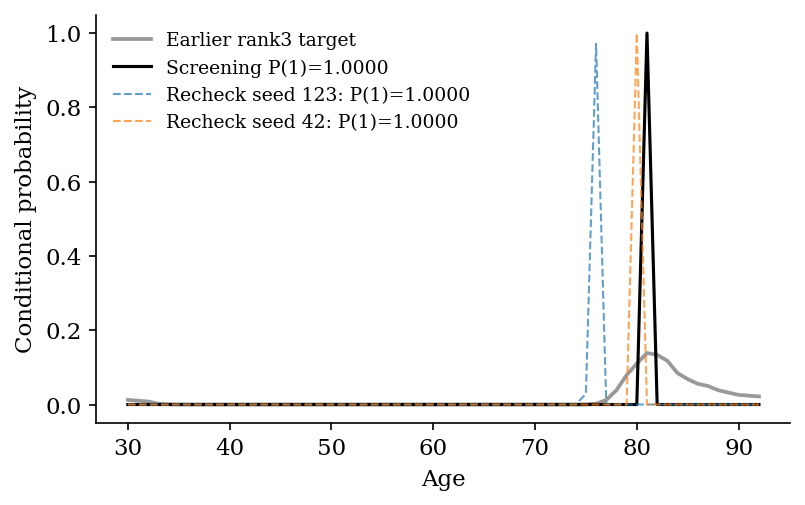

### Unpenalized #7: config317_p
Screening P(1)=1.0000; TV=0.8614; correlation=0.0791.

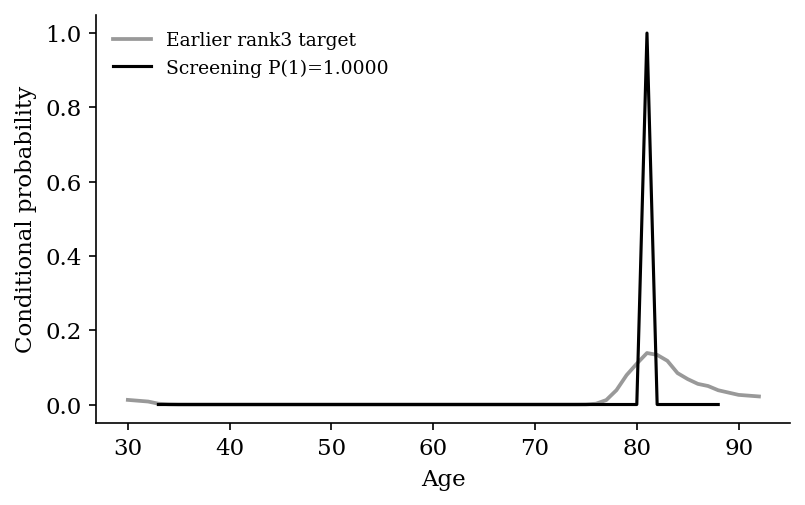

### Unpenalized #8: config255_n
Screening P(1)=1.0000; TV=0.8656; correlation=0.0837.

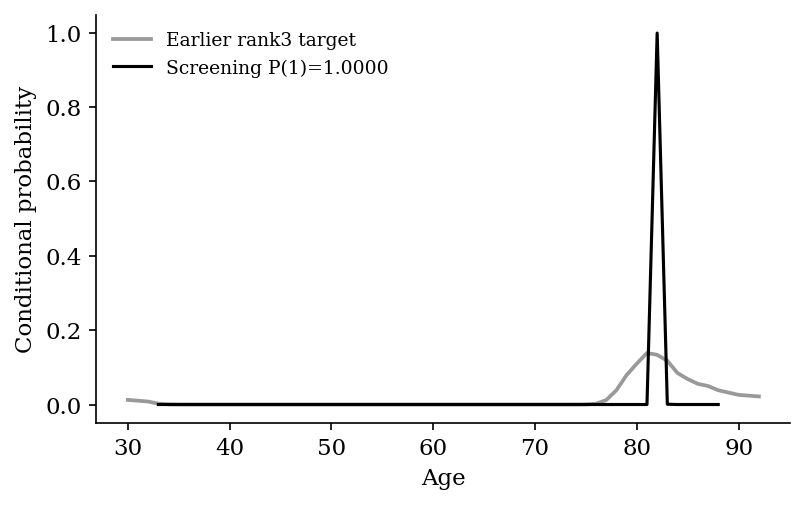

### Unpenalized #9: config031_n
Screening P(1)=1.0000; TV=0.8823; correlation=0.0837.

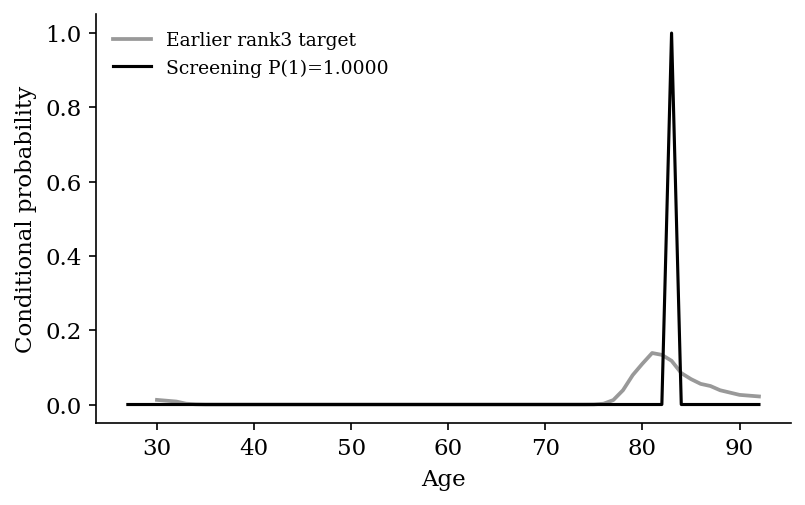

### Unpenalized #10: config150_n
Screening P(1)=1.0000; TV=0.8823; correlation=0.1399.

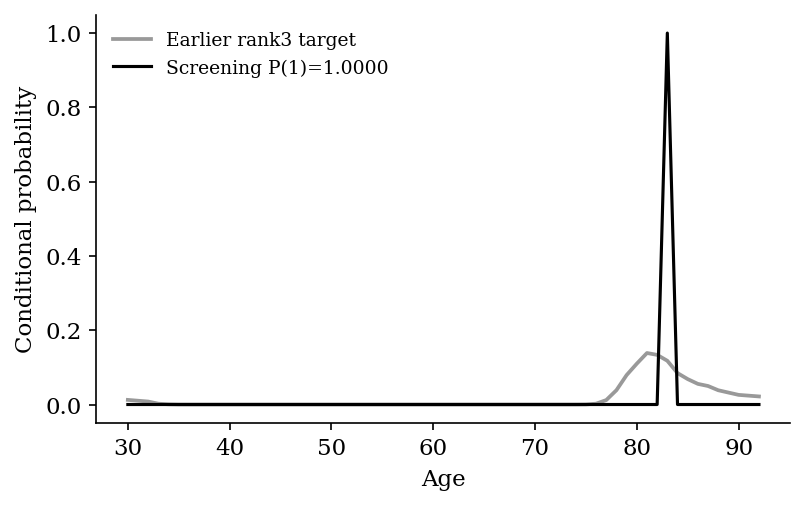

### Unpenalized #11: config262_p
Screening P(1)=1.0000; TV=0.8823; correlation=0.1399.

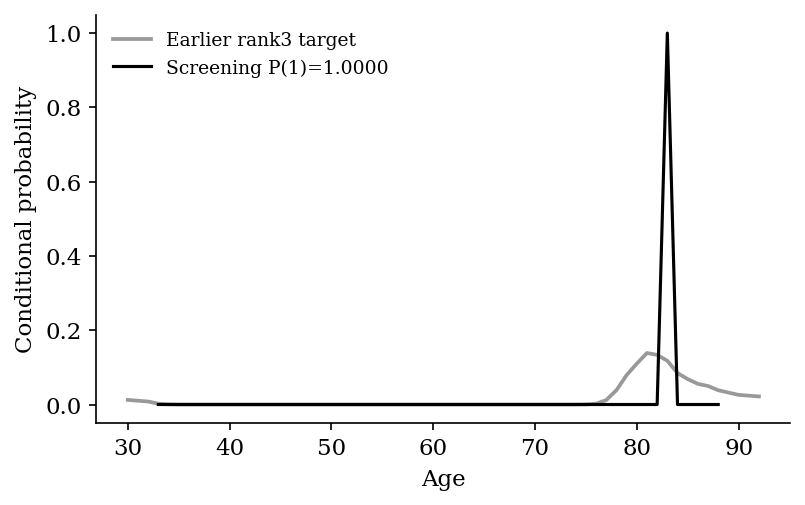

### Unpenalized #12: config255_p
Screening P(1)=1.0000; TV=0.8894; correlation=0.0837.

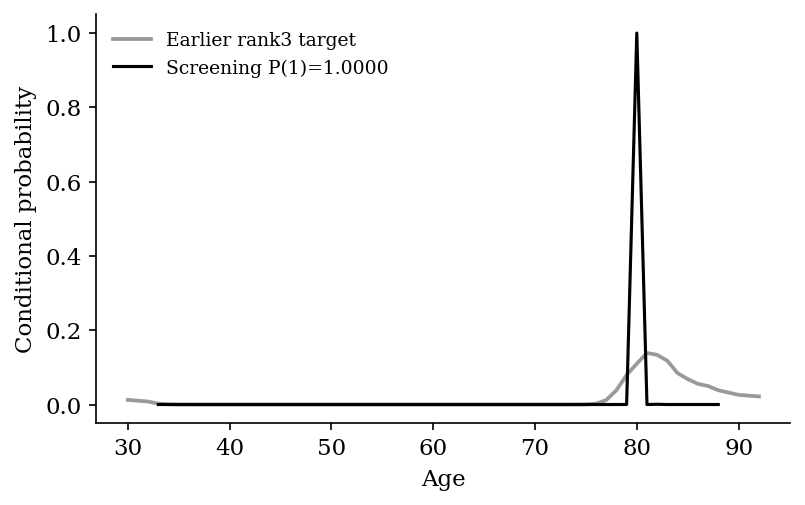

### Unpenalized #13: config157_n
Screening P(1)=1.0000; TV=0.9146; correlation=0.0515.

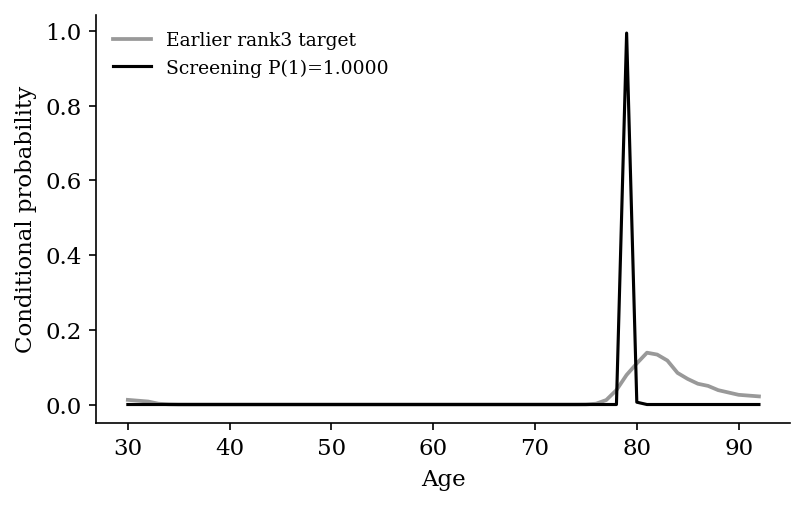

### Unpenalized #14: config262_n
Screening P(1)=1.0000; TV=0.9154; correlation=0.1399.

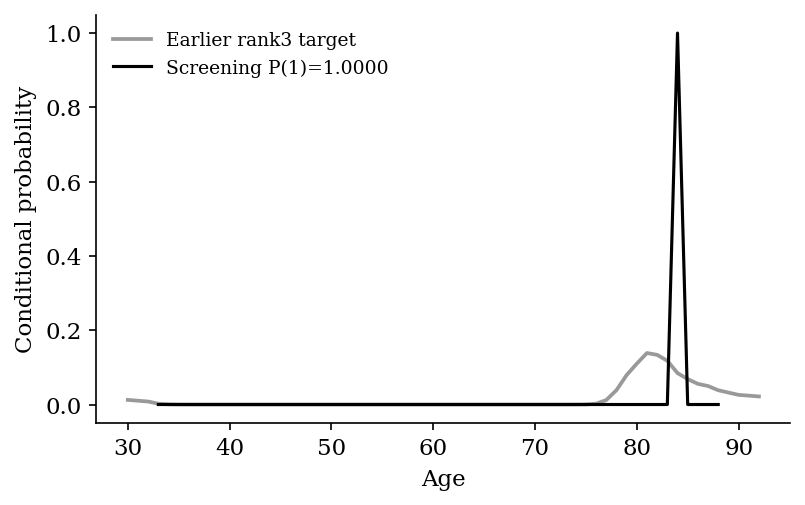

### Unpenalized #15: config269_n
Screening P(1)=1.0000; TV=0.9207; correlation=0.0515.

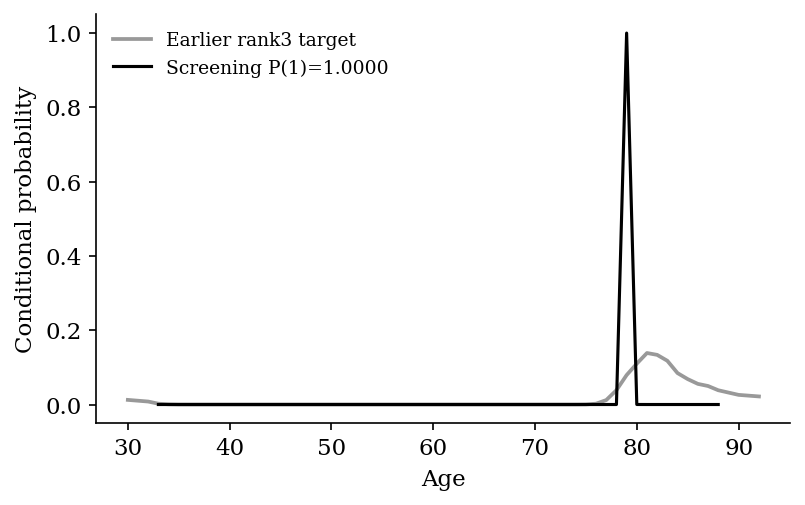

### Unpenalized #16: config037_p
Screening P(1)=1.0000; TV=0.9208; correlation=0.1734.

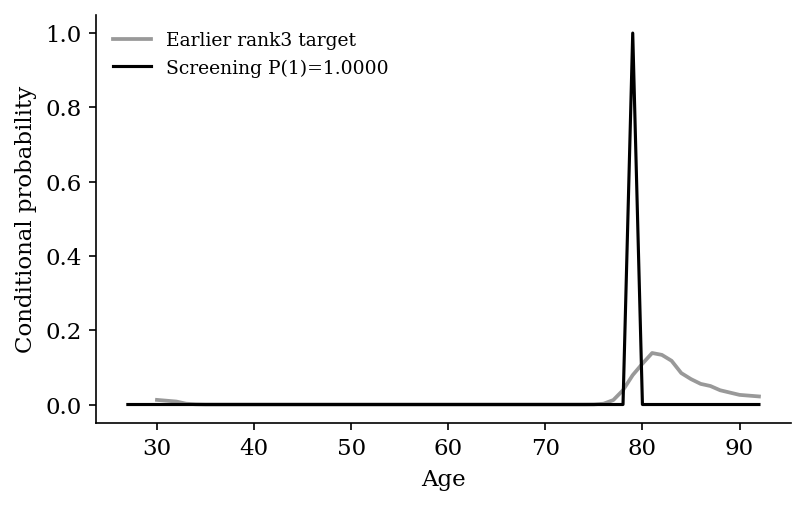

### Unpenalized #17: config038_n
Screening P(1)=1.0000; TV=0.9316; correlation=0.1399.

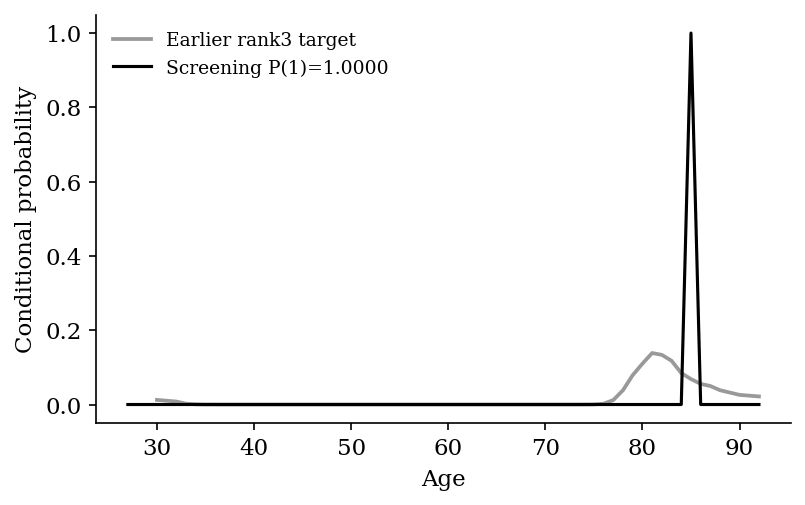

### Unpenalized #18: config094_p
Screening P(1)=1.0000; TV=0.9445; correlation=0.0379.

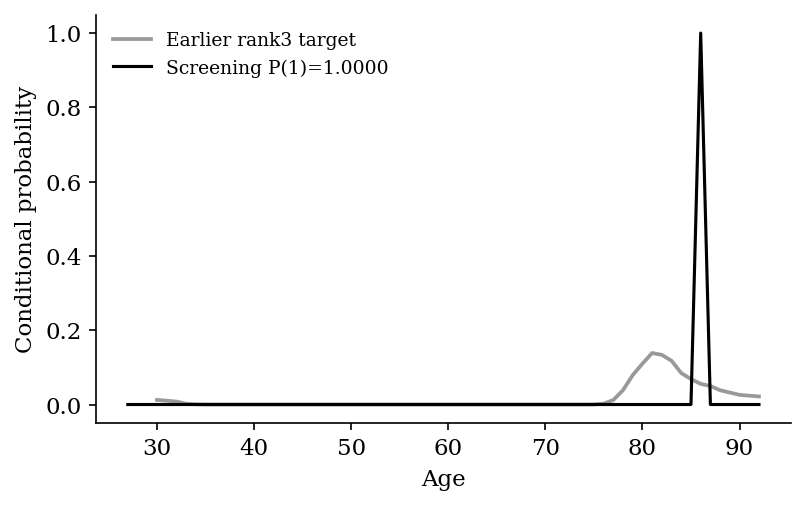

### Unpenalized #19: config257_n
Screening P(1)=1.0000; TV=0.9445; correlation=0.1829.

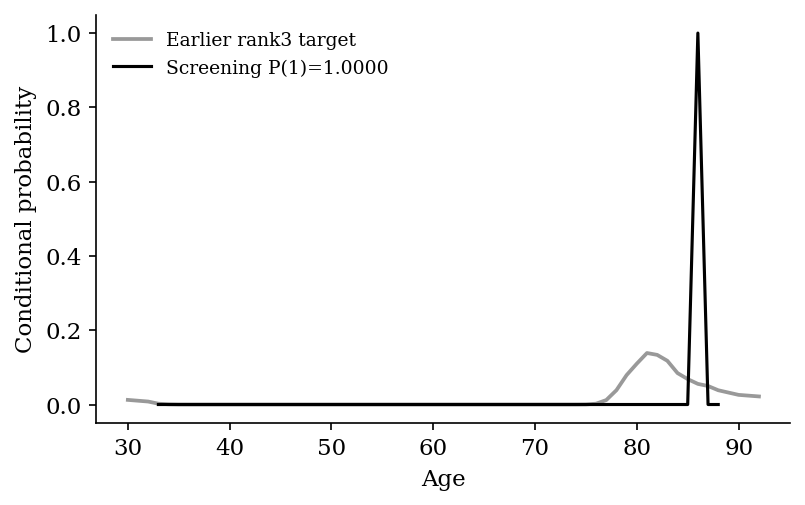

### Unpenalized #20: config319_p
Screening P(1)=1.0000; TV=0.9445; correlation=0.0234.

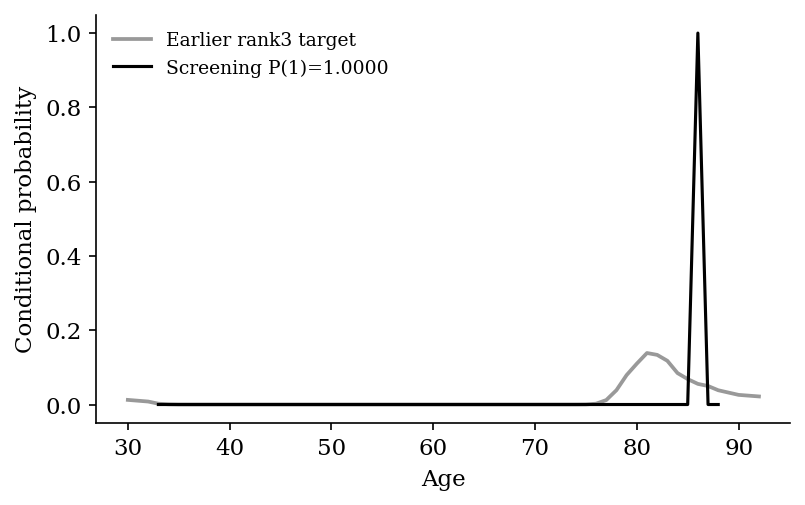

In [1]:

from pathlib import Path
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=Path('results/myocardial_gram_pair_1ce06b10b4f5/segmented')
summary=pd.read_csv(root/'summary.csv')
unpenalized=summary.loc[summary.penalty=='none'].copy()
unpenalized['loss_priority']=(unpenalized.aux_loss!='logistic').astype(int)
selected=unpenalized.sort_values(['loss_priority','TV_to_rank3','id']).head(20).copy()
assert len(selected)==20 and selected.penalty.eq('none').all()
print('Logistic auxiliary/segment fits prioritized; within each loss, ascending screening TV. No P(1) threshold.')
selected.insert(0,'subset_rank',range(1,len(selected)+1))
validation=pd.read_csv(root/'validation.csv')
checks=validation.groupby('id').agg(recheck_P1_min=('P_1','min'),recheck_P1_max=('P_1','max'),recheck_count=('P_1','size'))
selected=selected.merge(checks,left_on='id',right_index=True,how='left')
selected['recheck_count']=selected.recheck_count.fillna(0).astype(int)
cols=['subset_rank','id','P_1','TV_to_rank3','aux_loss','penalty','strength','method','budget','intercept','Delta','denominator','correlation','peak_age','mass_above55','recheck_count','recheck_P1_min','recheck_P1_max']
display(selected[cols].style.hide(axis='index').format(precision=5,na_rep='Not rechecked'))
target=pickle.load(open('results/myocardial_final_redo_e3d965cc4b9b/scenario_100_100_q10_seed123.pkl','rb'))
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
for row in selected.itertuples():
    result=pickle.load(open(row.checkpoint,'rb'))
    display(Markdown(f'### Unpenalized #{row.subset_rank}: {row.id}\n'
        f'Screening P(1)={row.P_1:.4f}; TV={row.TV_to_rank3:.4f}; correlation={row.correlation:.4f}.'))
    fig,ax=plt.subplots(figsize=(5.5,3.5))
    ax.plot(target['ages'],target['conditional'],color='.6',lw=1.8,label='Earlier rank3 target')
    ax.plot(result['ages'],result['conditional'],color='black',lw=1.5,label=f'Screening P(1)={row.P_1:.4f}')
    for check in validation.loc[validation.id==row.id].itertuples():
        checked=pickle.load(open(check.checkpoint,'rb'))
        ax.plot(checked['ages'],checked['conditional'],lw=1,ls='--',alpha=.7,label=f'Recheck seed {check.seed}: P(1)={check.P_1:.4f}')
    ax.set(xlabel='Age',ylabel='Conditional probability')
    ax.legend(frameon=False,fontsize=9);fig.tight_layout();plt.show()


## Top 20 unpenalized least-squares auxiliary/segment results

Completed **unbalanced segmented Gram** study. Both the initial auxiliary fit and the estimated-segment refits use exact, unpenalized least squares. The posterior WERM regression uses unpenalized finite-iteration logistic; the displayed solver and iteration budget refer to that logistic fit, not to LS. Select the twenty smallest **512-draw screening TV distances** to the earlier rank-3 curve, with no P(1) cutoff. All these LS screening configurations have P(1) numerically near one; that is not evidence of calibration. Available 1024-draw rechecks are tabulated and overlaid, and missing checks are explicitly marked. The best screening candidate had TV about 0.890, worsening to about 1.000 on recheck; the ranking must not be interpreted as a validated good match.

subset_rank,id,P_1,TV_to_rank3,aux_loss,penalty,strength,method,budget,intercept,Delta,denominator,correlation,peak_age,mass_above55,recheck_count,recheck_P1_min,recheck_P1_max
1,config226_p,1.00000,0.89002,squared,none,0.00000,fista,20,False,5,p,-0.00018,80.00000,1.00000,2,1.00000,1.00000
2,config114_p,1.00000,0.93157,squared,none,0.00000,fista,20,False,2,p,-0.00018,85.00000,1.00000,2,1.00000,1.00000
3,config003_p,1.00000,0.93157,squared,none,0.00000,fista,30,False,1,p,-0.00018,85.00000,1.00000,0,Not rechecked,Not rechecked
4,config115_p,1.00000,0.93157,squared,none,0.00000,fista,30,False,2,p,-0.00018,85.00000,1.00000,0,Not rechecked,Not rechecked
5,config129_p,1.00000,0.93157,squared,none,0.00000,gd,100,False,2,p,-0.00018,85.00000,1.00000,0,Not rechecked,Not rechecked
6,config227_p,1.00000,0.93157,squared,none,0.00000,fista,30,False,5,p,-0.00018,85.00000,1.00000,0,Not rechecked,Not rechecked
7,config241_p,1.00000,0.93157,squared,none,0.00000,gd,100,False,5,p,-0.00018,85.00000,1.00000,0,Not rechecked,Not rechecked
8,config230_p,1.00000,0.94566,squared,none,0.00000,lbfgs,8,False,5,p,-0.00018,87.00000,1.00000,0,Not rechecked,Not rechecked
9,config116_p,1.00000,0.95018,squared,none,0.00000,fista,50,False,2,p,-0.00018,87.00000,1.00000,0,Not rechecked,Not rechecked
10,config004_p,1.00000,0.95019,squared,none,0.00000,fista,50,False,1,p,-0.00018,87.00000,1.00000,0,Not rechecked,Not rechecked


### Unpenalized LS #1: config226_p
Screening P(1)=1.0000; TV=0.8900; correlation=-0.0002.

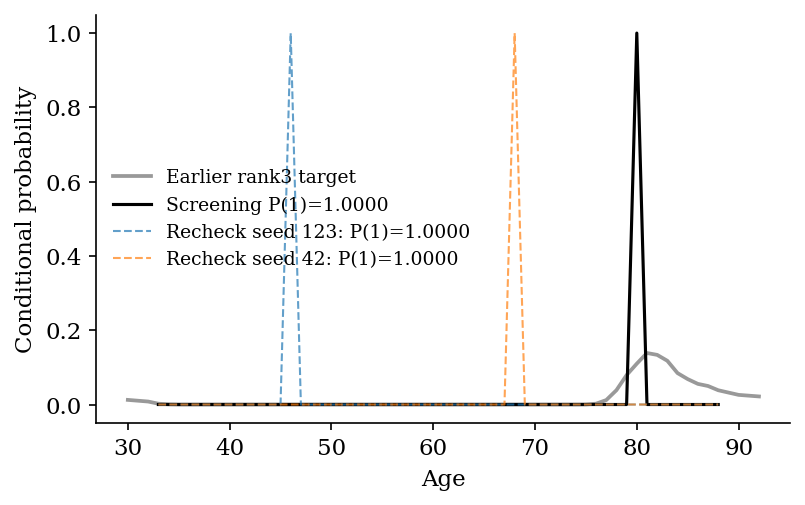

### Unpenalized LS #2: config114_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

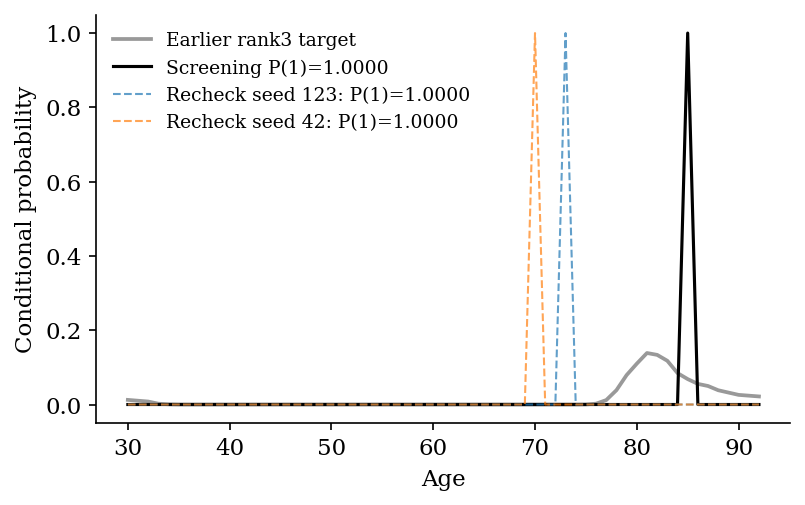

### Unpenalized LS #3: config003_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

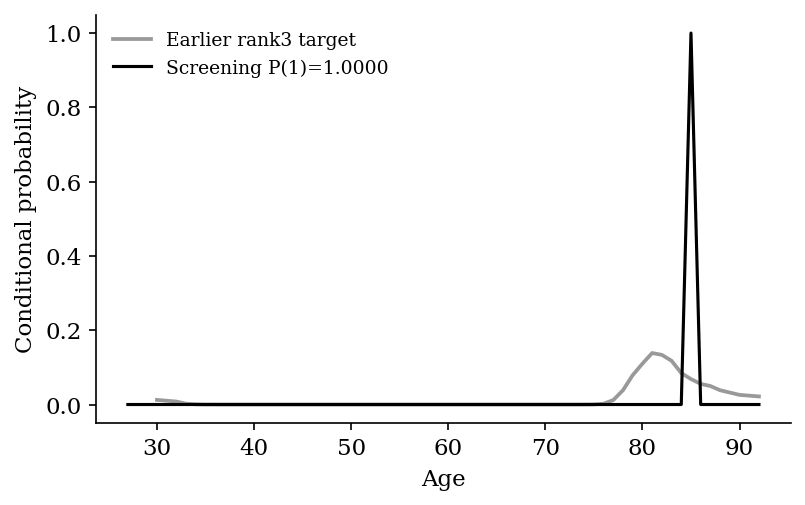

### Unpenalized LS #4: config115_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

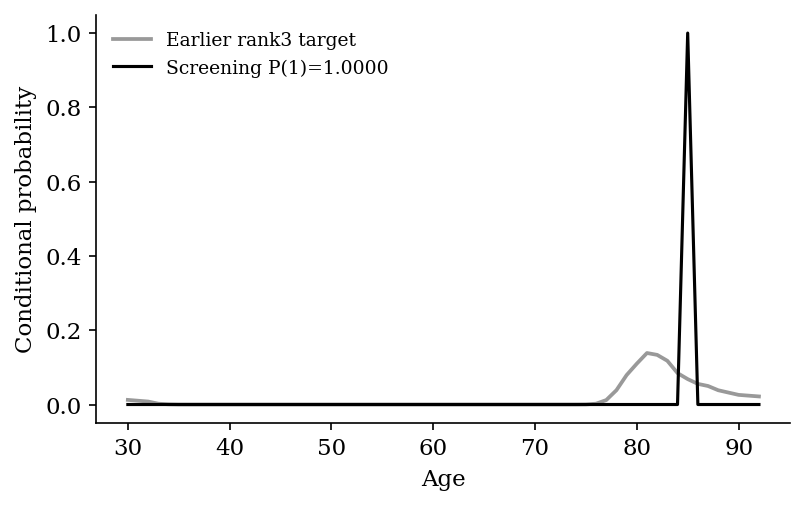

### Unpenalized LS #5: config129_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

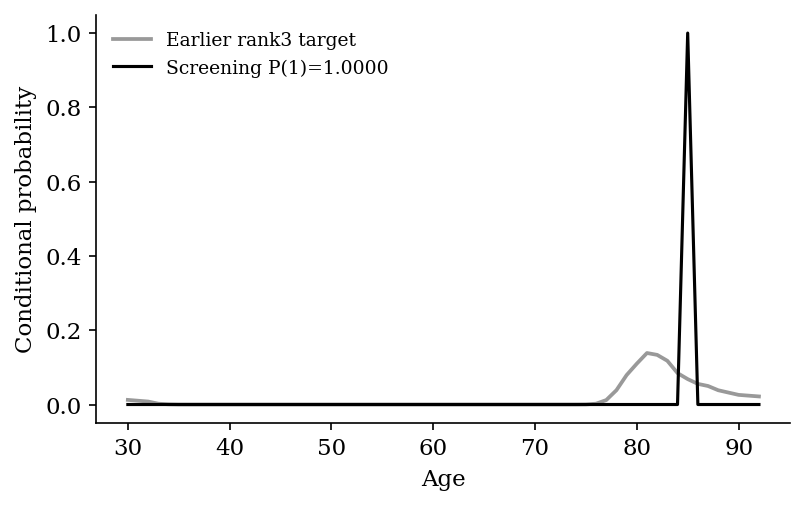

### Unpenalized LS #6: config227_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

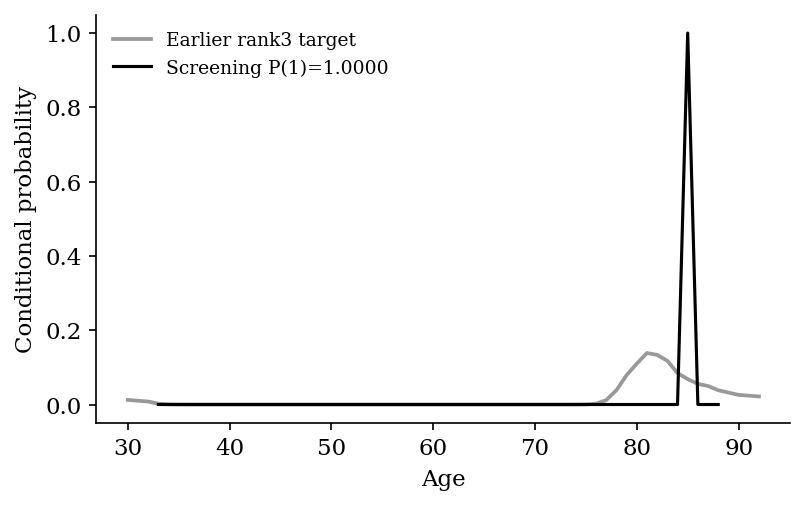

### Unpenalized LS #7: config241_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

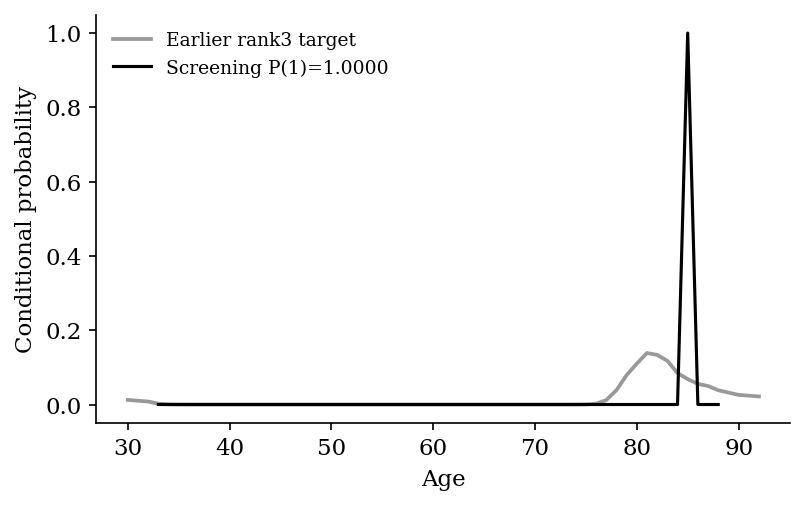

### Unpenalized LS #8: config230_p
Screening P(1)=1.0000; TV=0.9457; correlation=-0.0002.

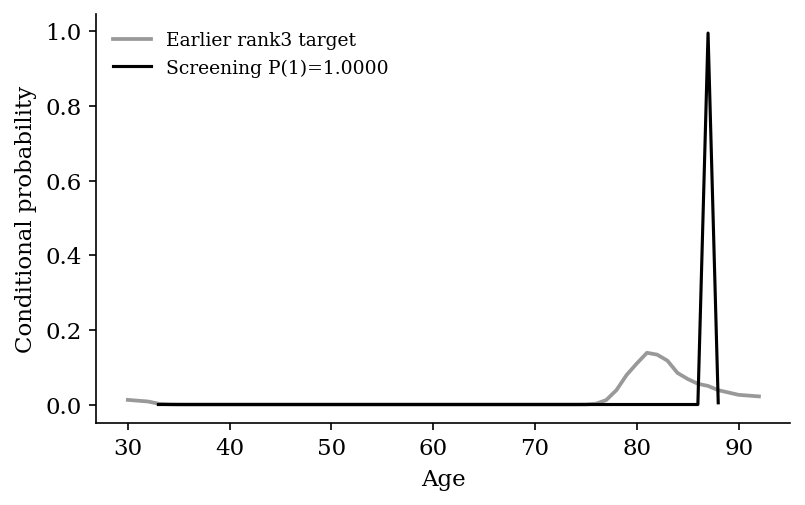

### Unpenalized LS #9: config116_p
Screening P(1)=1.0000; TV=0.9502; correlation=-0.0002.

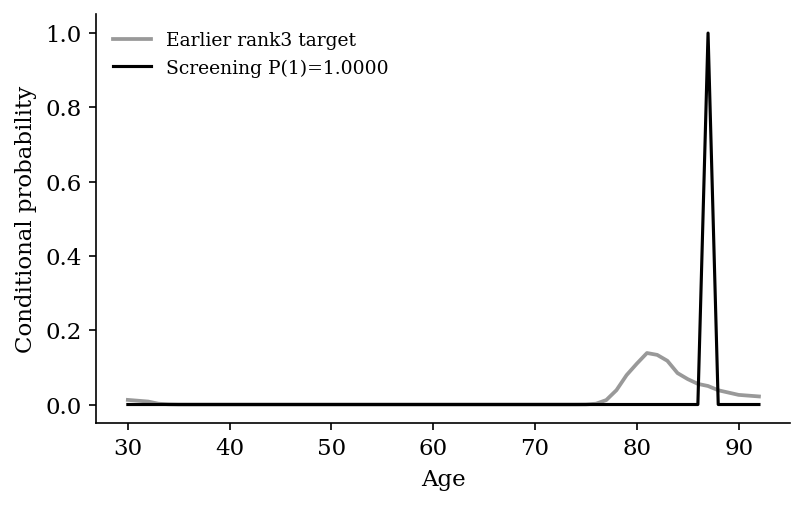

### Unpenalized LS #10: config004_p
Screening P(1)=1.0000; TV=0.9502; correlation=-0.0002.

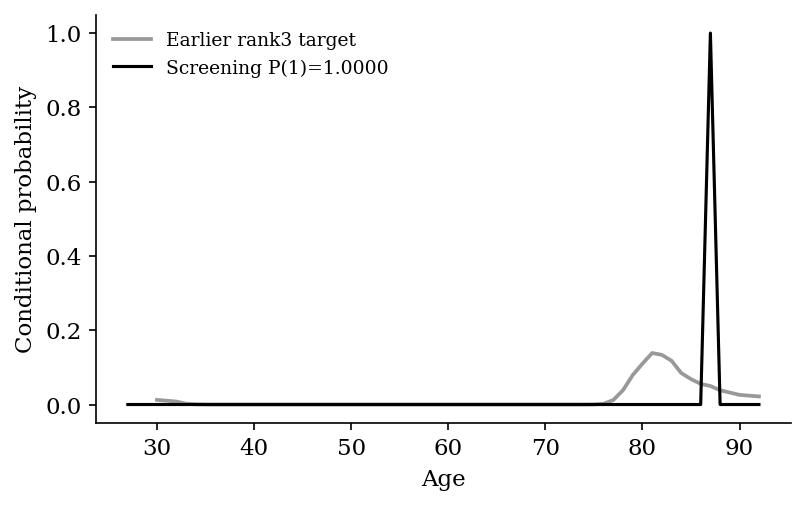

### Unpenalized LS #11: config228_p
Screening P(1)=1.0000; TV=0.9502; correlation=-0.0002.

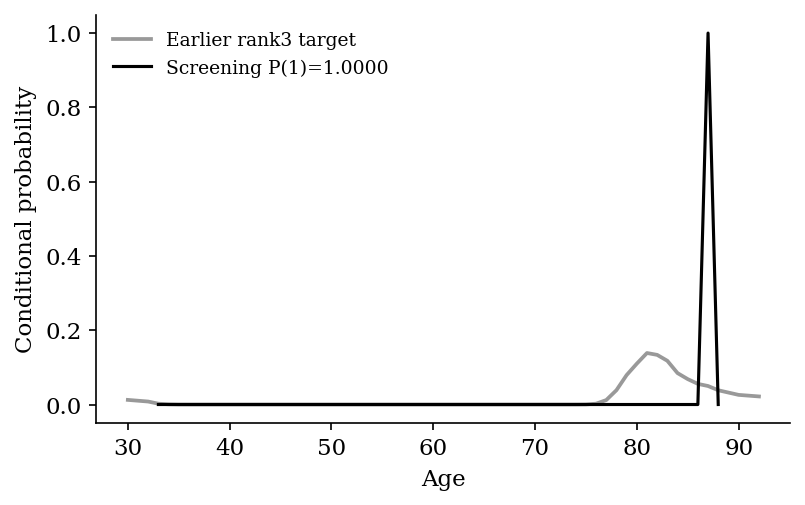

### Unpenalized LS #12: config118_p
Screening P(1)=1.0000; TV=0.9503; correlation=-0.0002.

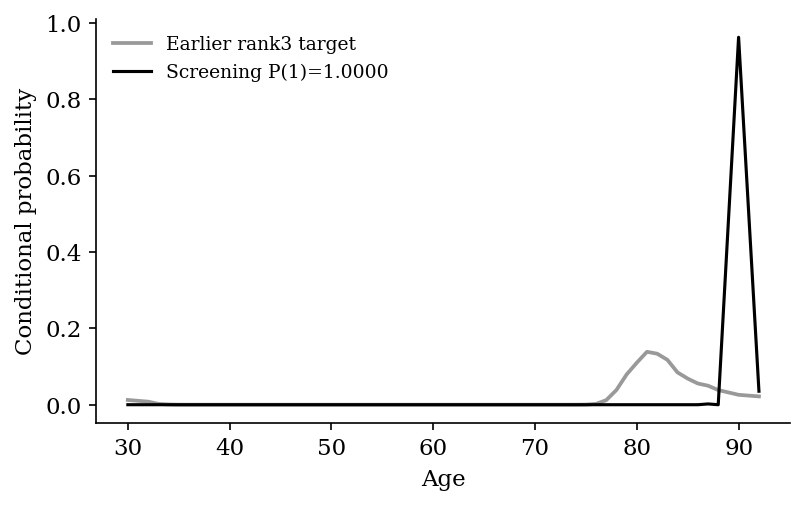

### Unpenalized LS #13: config006_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

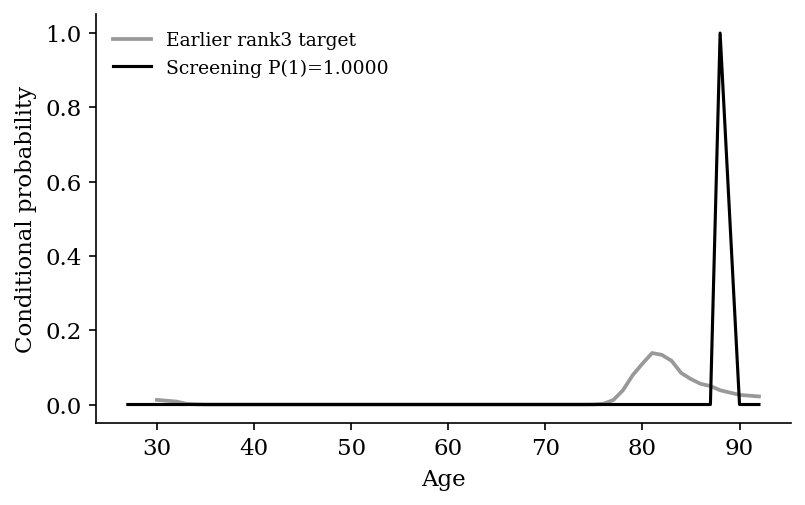

### Unpenalized LS #14: config007_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

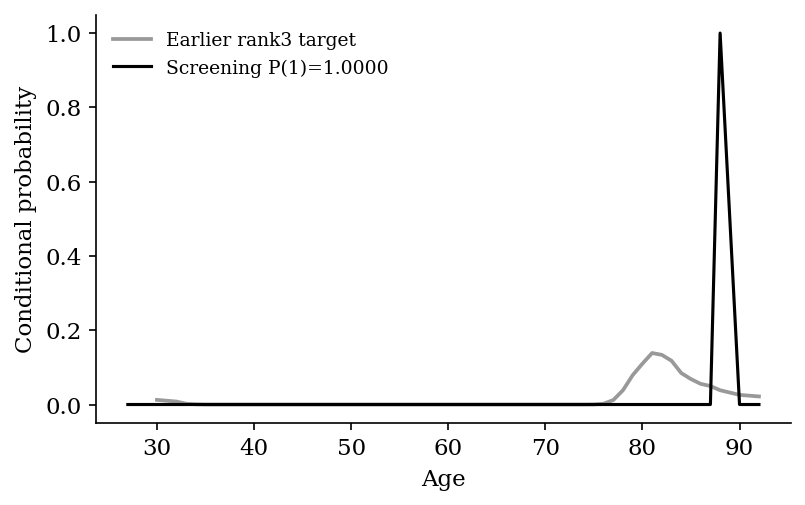

### Unpenalized LS #15: config005_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

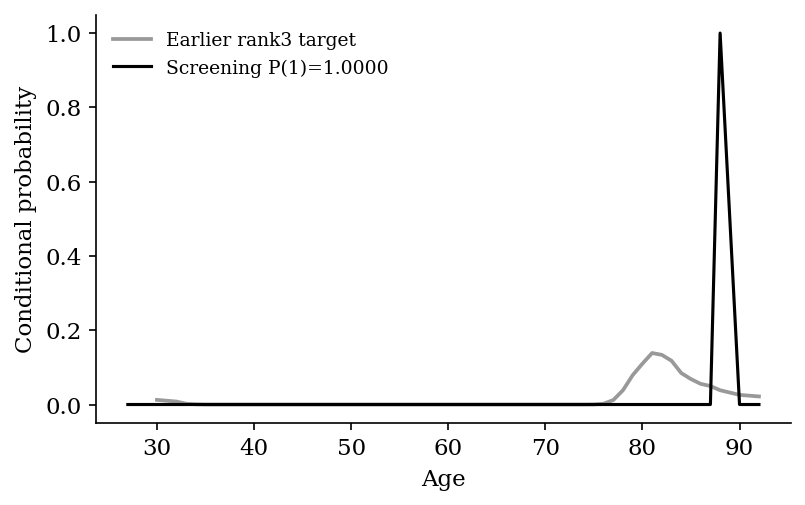

### Unpenalized LS #16: config008_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

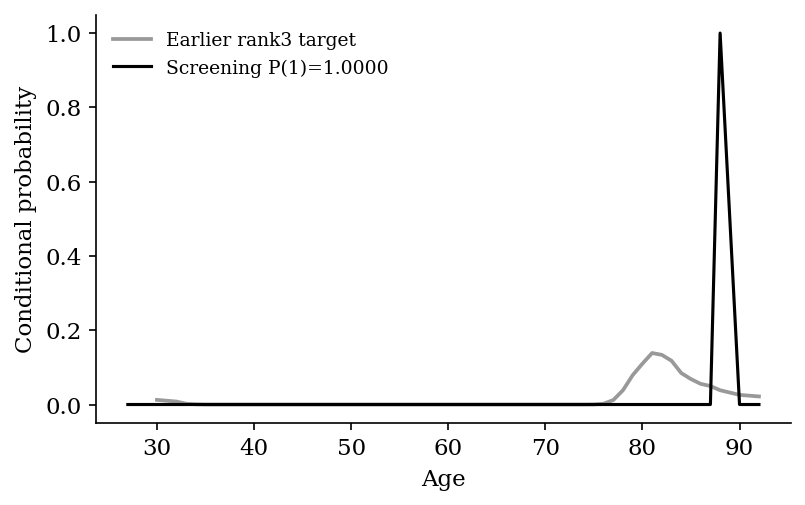

### Unpenalized LS #17: config009_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

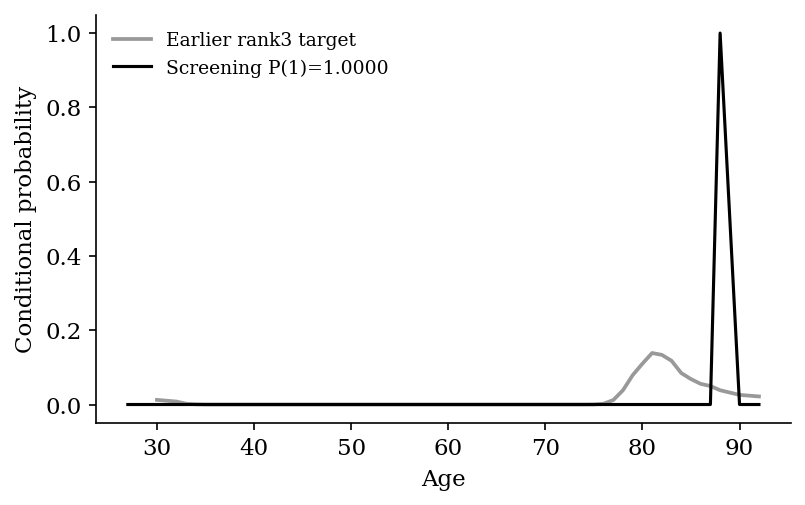

### Unpenalized LS #18: config010_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

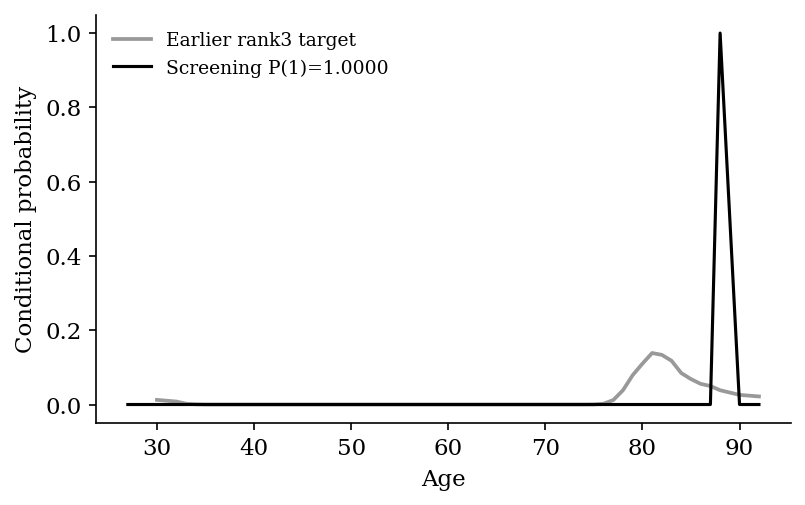

### Unpenalized LS #19: config011_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

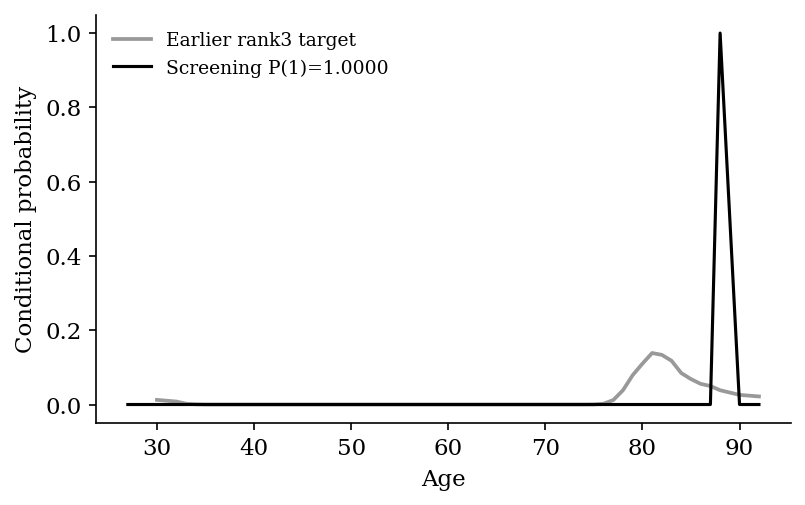

### Unpenalized LS #20: config229_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

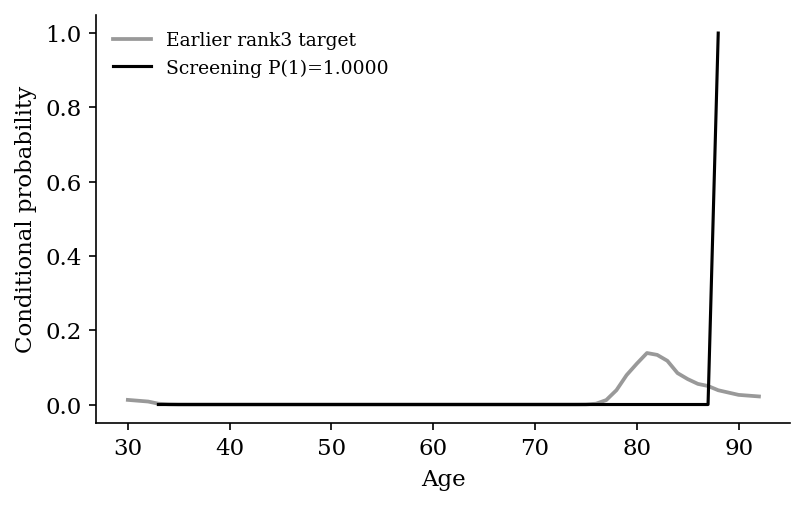

In [1]:

from pathlib import Path
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=Path('results/myocardial_gram_pair_1ce06b10b4f5/segmented')
summary=pd.read_csv(root/'summary.csv')
selected=summary.loc[(summary.penalty=='none') & (summary.aux_loss=='squared')].sort_values(['TV_to_rank3','id']).head(20).copy()
assert len(selected)==20 and selected.penalty.eq('none').all() and selected.aux_loss.eq('squared').all()
selected.insert(0,'subset_rank',range(1,len(selected)+1))
validation=pd.read_csv(root/'validation.csv')
checks=validation.groupby('id').agg(recheck_P1_min=('P_1','min'),recheck_P1_max=('P_1','max'),recheck_count=('P_1','size'))
selected=selected.merge(checks,left_on='id',right_index=True,how='left')
selected['recheck_count']=selected.recheck_count.fillna(0).astype(int)
cols=['subset_rank','id','P_1','TV_to_rank3','aux_loss','penalty','strength','method','budget','intercept','Delta','denominator','correlation','peak_age','mass_above55','recheck_count','recheck_P1_min','recheck_P1_max']
display(selected[cols].style.hide(axis='index').format(precision=5,na_rep='Not rechecked'))
target=pickle.load(open('results/myocardial_final_redo_e3d965cc4b9b/scenario_100_100_q10_seed123.pkl','rb'))
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
for row in selected.itertuples():
    result=pickle.load(open(row.checkpoint,'rb'))
    display(Markdown(f'### Unpenalized LS #{row.subset_rank}: {row.id}\n'
        f'Screening P(1)={row.P_1:.4f}; TV={row.TV_to_rank3:.4f}; correlation={row.correlation:.4f}.'))
    fig,ax=plt.subplots(figsize=(5.5,3.5))
    ax.plot(target['ages'],target['conditional'],color='.6',lw=1.8,label='Earlier rank3 target')
    ax.plot(result['ages'],result['conditional'],color='black',lw=1.5,label=f'Screening P(1)={row.P_1:.4f}')
    for check in validation.loc[validation.id==row.id].itertuples():
        checked=pickle.load(open(check.checkpoint,'rb'))
        ax.plot(checked['ages'],checked['conditional'],lw=1,ls='--',alpha=.7,label=f'Recheck seed {check.seed}: P(1)={check.P_1:.4f}')
    ax.set(xlabel='Age',ylabel='Conditional probability')
    ax.legend(frameon=False,fontsize=9);fig.tight_layout();plt.show()
